In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Rc = 10.0
Rt = 15.0
N = 60
S = 1.0

Dc = np.array([1.2627, 0.3543])
Rmc = np.array([0.02619, 0.1210])
Ac = np.array([0.01207, 0.1210])
Fc = np.array([0.008476, 0.18514])

Dr = np.array([1.13, 0.16])
Rmr = np.array([0.0494, 0.0197])
Ar = np.array([0.0004, 0.0197])
Fr = np.array([0.0, 0.0])

Sc = Rmc[0] - Ac[0]
Sr = Rmr[0] - Ar[0]

In [ ]:
def make_grid(reflector):
    R = Rt if reflector else Rc
    n = N if reflector else N
    r = np.linspace(0, R, n + 1)
    h = r[1] - r[0]
    return r, h

def diffusion_matrix(r, h, D, removal):
    n = len(r) - 1
    A = np.zeros((n, n))

    for i in range(n):
        if i == 0:
            A[i, i] = 6 * D[i] / h**2 + removal[i]
            A[i, i+1] = -6 * D[i] / h**2

        else:
            rp = (r[i] + r[i+1]) / 2
            rm = (r[i] + r[i-1]) / 2

            Dp = 2 * D[i] * D[min(i+1, n-1)] / (
                D[i] + D[min(i+1, n-1)]
            )
            Dm = 2 * D[i] * D[i-1] / (D[i] + D[i-1])

            A[i, i] = (rp**2 * Dp + rm**2 * Dm) / (
                r[i]**2 * h**2
            ) + removal[i]

            A[i, i-1] = -rm**2 * Dm / (r[i]**2 * h**2)
            A[i, i] += 0
            if i < n-1:
                A[i, i+1] = -rp**2 * Dp / (r[i]**2 * h**2)

    return A

In [5]:
def properties(r, reflector):
    n = len(r) - 1

    D = np.zeros((2, n))
    Rm = np.zeros((2, n))
    A = np.zeros((2, n))
    F = np.zeros((2, n))
    Scat = np.zeros(n)

    for i in range(n):
        if reflector and r[i] >= Rc:
            D[:, i] = Dr
            Rm[:, i] = Rmr
            A[:, i] = Ar
            F[:, i] = Fr
            Scat[i] = Sr
        else:
            D[:, i] = Dc
            Rm[:, i] = Rmc
            A[:, i] = Ac
            F[:, i] = Fc
            Scat[i] = Sc

    return D, Rm, A, F, Scat

def source_problem(reflector):
    r, h = make_grid(reflector)
    D, Rm, A, F, Scat = properties(r, reflector)
    n = len(r) - 1

    A1 = diffusion_matrix(r, h, D[0], Rm[0])
    A2 = diffusion_matrix(r, h, D[1], A[1])

    L = np.zeros((2*n, 2*n))
    L[:n, :n] = A1
    L[n:, n:] = A2
    L[n:, :n] = -np.diag(Scat)

    b = np.zeros(2*n)
    b[:n] = S

    flux = np.linalg.solve(L, b)

    return r[:-1], flux[:n], flux[n:]

def critical_problem(reflector):
    r, h = make_grid(reflector)
    D, Rm, A, F, Scat = properties(r, reflector)
    n = len(r) - 1

    A1 = diffusion_matrix(r, h, D[0], Rm[0])
    A2 = diffusion_matrix(r, h, D[1], A[1])

    L = np.zeros((2*n, 2*n))
    L[:n, :n] = A1
    L[n:, n:] = A2
    L[n:, :n] = -np.diag(Scat)

    FM = np.zeros((2*n, 2*n))
    FM[:n, :n] = np.diag(F[0])
    FM[:n, n:] = np.diag(F[1])

    K = np.linalg.solve(L, FM)
    values, vectors = np.linalg.eig(K)

    j = np.argmax(values.real)
    k = values[j].real

    flux = vectors[:, j].real
    flux = flux / np.max(np.abs(flux[:n]))

    return r[:-1], flux[:n], flux[n:], k


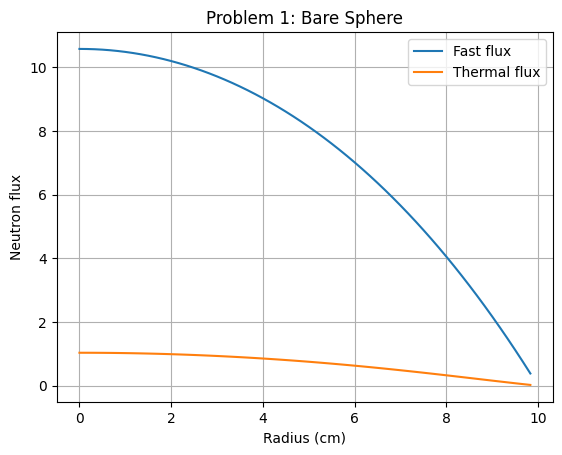

In [6]:
r, fast, thermal = source_problem(False)

plt.plot(r, fast, label="Fast flux")
plt.plot(r, thermal, label="Thermal flux")
plt.xlabel("Radius (cm)")
plt.ylabel("Neutron flux")
plt.title("Problem 1: Bare Sphere")
plt.legend()
plt.grid()
plt.show()

Bare sphere multiplication factor = 0.16735081451840564
Critical fast nuSigma_f = 0.050648095286490454
Critical thermal nuSigma_f = 1.1062987684451209


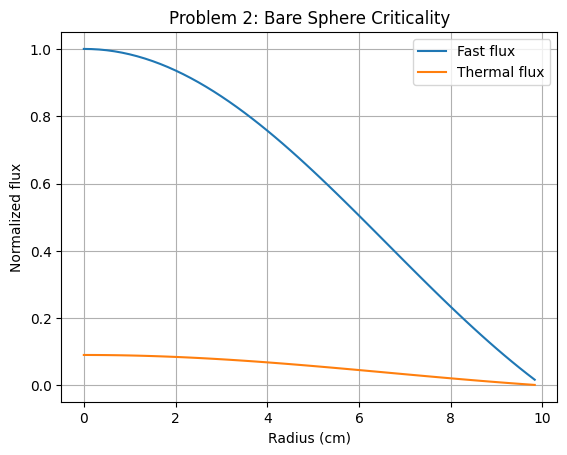

In [8]:
r, fast, thermal, k = critical_problem(False)

print("Bare sphere multiplication factor =", k)
print("Critical fast nuSigma_f =", Fc[0] / k)
print("Critical thermal nuSigma_f =", Fc[1] / k)

plt.plot(r, fast, label="Fast flux")
plt.plot(r, thermal, label="Thermal flux")
plt.xlabel("Radius (cm)")
plt.ylabel("Normalized flux")
plt.title("Problem 2: Bare Sphere Criticality")
plt.legend()
plt.grid()
plt.show()

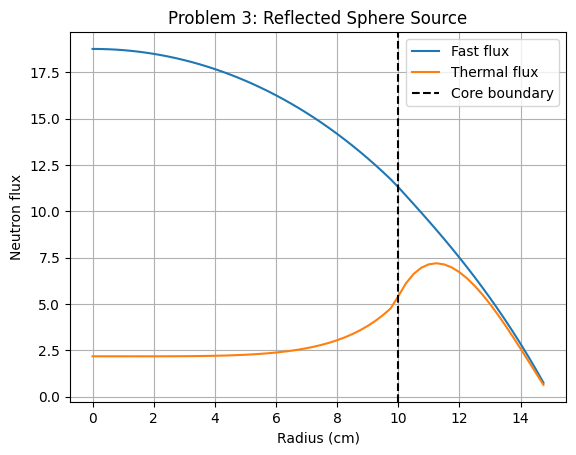

Reflected sphere multiplication factor = 0.3887878130082403


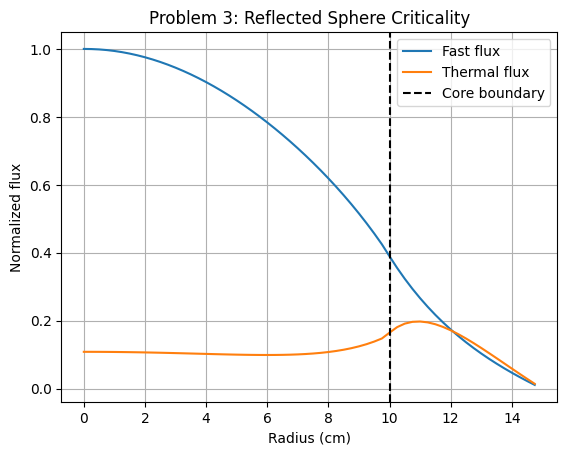

In [9]:
r, fast, thermal = source_problem(True)

plt.plot(r, fast, label="Fast flux")
plt.plot(r, thermal, label="Thermal flux")
plt.axvline(Rc, color="black", linestyle="--", label="Core boundary")
plt.xlabel("Radius (cm)")
plt.ylabel("Neutron flux")
plt.title("Problem 3: Reflected Sphere Source")
plt.legend()
plt.grid()
plt.show()

r, fast, thermal, k = critical_problem(True)

print("Reflected sphere multiplication factor =", k)

plt.plot(r, fast, label="Fast flux")
plt.plot(r, thermal, label="Thermal flux")
plt.axvline(Rc, color="black", linestyle="--", label="Core boundary")
plt.xlabel("Radius (cm)")
plt.ylabel("Normalized flux")
plt.title("Problem 3: Reflected Sphere Criticality")
plt.legend()
plt.grid()
plt.show()